# Lecture 18: Singular Value Decomposition

The singular value decomposition (SVD) factors any real matrix into orthogonal changes of coordinates and nonnegative scaling. These notes follow the lecture sequence and retain its annotated diagrams. All matrices are real unless stated otherwise; for complex matrices, replace transposes with conjugate transposes.

## 1. Full Singular Value Decomposition

For every $A\in\mathbb R^{m\times n}$, there exist orthogonal matrices $U\in\mathbb R^{m\times m}$ and $V\in\mathbb R^{n\times n}$ such that
$$A=U\Sigma V^T,\qquad \Sigma\in\mathbb R^{m\times n}.$$
The rectangular diagonal matrix $\Sigma$ has $k=\min(m,n)$ diagonal entries, ordered as
$$\sigma_1\ge\sigma_2\ge\cdots\ge\sigma_k\ge0.$$
These are the **singular values**. The columns $u_i$ of $U$ are **left singular vectors**; the columns $v_i$ of $V$ are **right singular vectors**. The rows of $V^T$ are $v_i^T$.

Orthogonality means $U^TU=UU^T=I_m$ and $V^TV=VV^T=I_n$. Thus $U^{-1}=U^T$ and $V^{-1}=V^T$. SVD exists even when $A$ is rectangular, singular, or not diagonalizable.

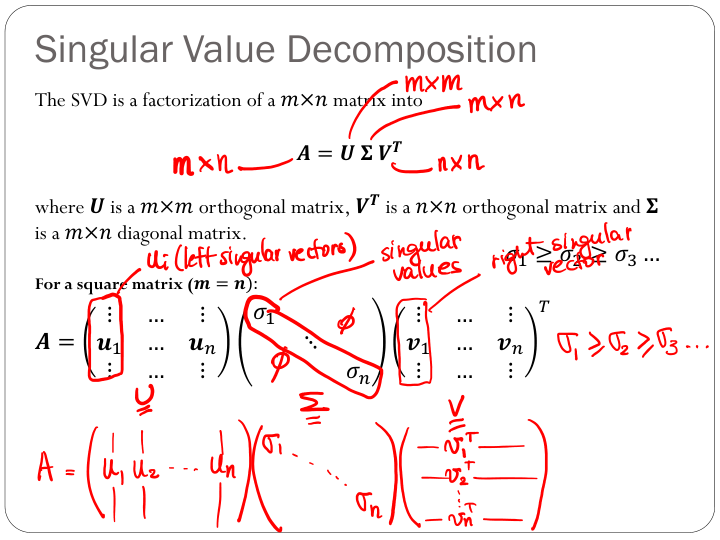

<details>
<summary>Example: Read the factor dimensions</summary>

Let $A\in\mathbb R^{7\times4}$. Give the dimensions of its full SVD factors.

<details>
<summary>Solution</summary>

$U$: $7\times7$; $\Sigma$: $7\times4$; $V$: $4\times4$; $V^T$: $4\times4$. The product has shape $(7\times7)(7\times4)(4\times4)=7\times4$. There are four singular values, some possibly zero.

</details>
</details>

### Geometric interpretation

For an input $x$, the product $Ax=U\Sigma V^Tx$ first expresses $x$ in the right singular vector basis, then scales its coordinates, then expresses the result in the left singular vector basis. Orthogonal transformations preserve Euclidean lengths; all stretching occurs in $\Sigma$.
$$Av_i=\sigma_i u_i\quad(1\le i\le k).$$
If $\sigma_i=0$, the direction $v_i$ is mapped to zero. For a wide matrix, additional right singular vectors also lie in the null space. SVD is not generally an eigenvalue decomposition: left and right directions may differ, and singular values are nonnegative even when eigenvalues are negative.

<details>
<summary>Example: Singular values versus eigenvalues</summary>

Find an SVD of $A=\operatorname{diag}(-3,2)$.

<details>
<summary>Solution</summary>

One choice is $U=\operatorname{diag}(-1,1)$, $\Sigma=\operatorname{diag}(3,2)$, and $V=I_2$. The eigenvalues are $-3,2$, while the singular values are $3,2$. The sign can be absorbed into a singular vector.

</details>
</details>

## 2. Reduced SVD

The lecture uses $k=\min(m,n)$ for the **reduced SVD**:
$$A=U_R\Sigma_R V_R^T,$$
where $U_R\in\mathbb R^{m\times k}$, $\Sigma_R\in\mathbb R^{k\times k}$, and $V_R\in\mathbb R^{n\times k}$. Its columns are orthonormal:
$$U_R^TU_R=I_k,\qquad V_R^TV_R=I_k.$$
A rectangular matrix with orthonormal columns is not a square orthogonal matrix. In general $U_RU_R^T\ne I_m$ or $V_RV_R^T\ne I_n$. These products are orthogonal projectors.

### Tall matrices: m > n

The last $m-n$ rows of full $\Sigma$ are zero, so the corresponding columns of $U$ do not contribute:
$$A=\underbrace{U_R}_{m\times n}\underbrace{\Sigma_R}_{n\times n}\underbrace{V^T}_{n\times n}.$$
Only $U$ loses columns; $V_R=V$.

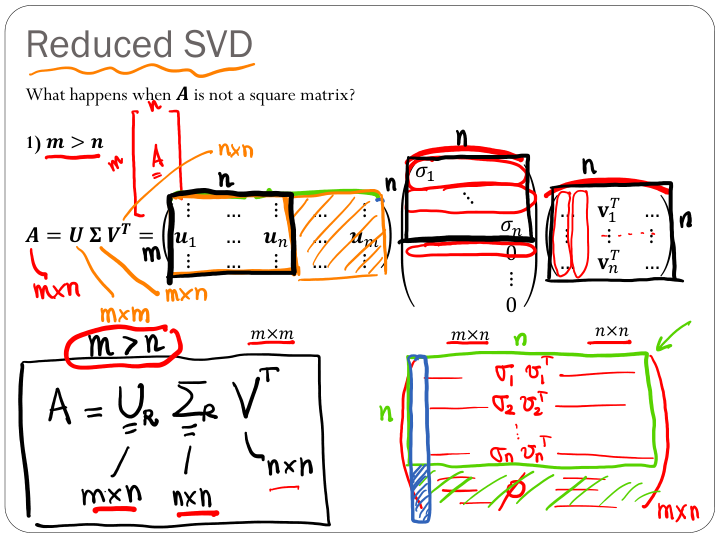

### Wide matrices: n > m

The last $n-m$ columns of full $\Sigma$ are zero. Only the first $m$ rows of $V^T$ contribute:
$$A=\underbrace{U}_{m\times m}\underbrace{\Sigma_R}_{m\times m}\underbrace{V_R^T}_{m\times n}.$$
Here $U_R=U$ and $V_R$ contains the first $m$ columns of $V$. The $n\times m$ label printed below the rectangular middle factor in the slide is a dimension typo: full $\Sigma$ must be $m\times n$.

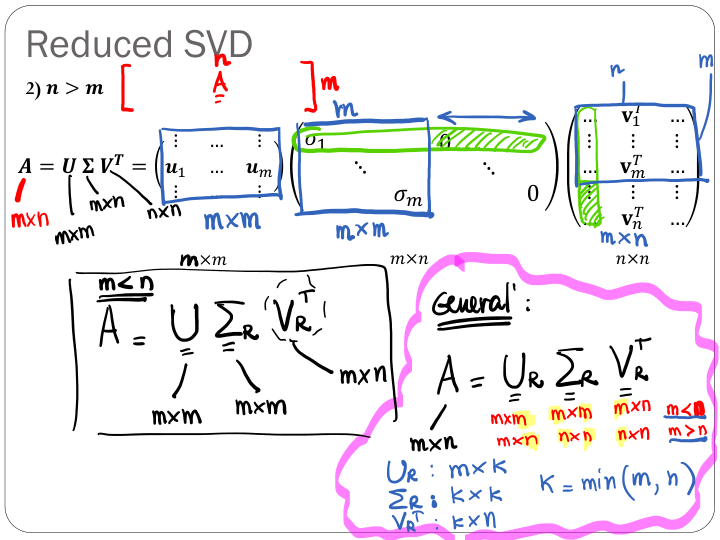

### Reduced form versus compact rank form

Reduced SVD retains $k=\min(m,n)$ singular values, including zeros. If $r=\operatorname{rank}(A)<k$, the **compact rank form** retains only the $r$ positive singular values:
$$A=U_r\Sigma_rV_r^T,\quad U_r\in\mathbb R^{m\times r},\quad\Sigma_r\in\mathbb R^{r\times r},\quad V_r\in\mathbb R^{n\times r}.$$
Both factorizations reproduce $A$ exactly. Retaining fewer than $r$ positive terms instead gives a truncated approximation. Terminology varies across texts, so always check the stated dimensions.

<details>
<summary>Example: A wide rank deficient matrix</summary>

For a $3\times5$ matrix of rank $2$, list the dimensions for full, reduced, and compact rank forms.

<details>
<summary>Solution</summary>

Full: $U$ is $3\times3$, $\Sigma$ is $3\times5$, $V^T$ is $5\times5$.

Reduced: $U_R$ is $3\times3$, $\Sigma_R$ is $3\times3$, $V_R^T$ is $3\times5$. The third singular value is zero.

Compact rank: $U_r$ is $3\times2$, $\Sigma_r$ is $2\times2$, $V_r^T$ is $2\times5$. The right null space has dimension $5-2=3$.

</details>
</details>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
A = np.array([[1., 2., 3.], [0., 1., 1.], [1., 0., 1.], [2., 1., 3.]])
U, s, Vt = np.linalg.svd(A, full_matrices=True)
Sigma = np.zeros(A.shape)
np.fill_diagonal(Sigma, s)
Ur, sr, Vtr = np.linalg.svd(A, full_matrices=False)
assert np.allclose(A, U @ Sigma @ Vt)
assert np.allclose(A, (Ur * sr) @ Vtr)
assert np.allclose(U.T @ U, np.eye(4))
assert np.allclose(Vt @ Vt.T, np.eye(3))
print('Full:', U.shape, Sigma.shape, Vt.shape)
print('Reduced:', Ur.shape, sr.shape, Vtr.shape)
print('Singular values:', s)

Full: (4, 4) (4, 3) (3, 3)
Reduced: (4, 3) (3,) (3, 3)
Singular values: [5.477226 1.414214 0.      ]


## 3. The Products Sigma Transpose Sigma and Sigma Sigma Transpose

For full $\Sigma$, the two products are square but can have different sizes:
$$\Sigma^T\Sigma\in\mathbb R^{n\times n},\qquad\Sigma\Sigma^T\in\mathbb R^{m\times m}.$$
They contain $\sigma_1^2,\ldots,\sigma_k^2$ on their diagonals, with additional zeros as needed. For $m>n$, $\Sigma^T\Sigma=\Sigma_R^2$ while $\Sigma\Sigma^T$ has $m-n$ extra zeros. For $n>m$, $\Sigma\Sigma^T=\Sigma_R^2$ while $\Sigma^T\Sigma$ has $n-m$ extra zeros.

The notation $\Sigma^2$ is appropriate for square $\Sigma_R$. For a rectangular full factor, write $\Sigma^T\Sigma$ or $\Sigma\Sigma^T$ explicitly.

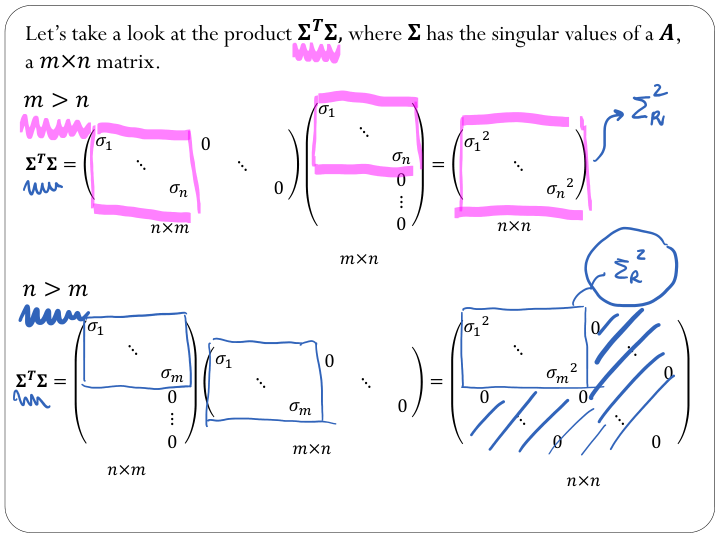

<details>
<summary>Example: Extra zero eigenvalues</summary>

A $2\times4$ matrix has singular values $5$ and $2$. What are the eigenvalues of $A^TA$ and $AA^T$?

<details>
<summary>Solution</summary>

$A^TA$ is $4\times4$ and has eigenvalues $25,4,0,0$. $AA^T$ is $2\times2$ and has eigenvalues $25,4$. Both share the same nonzero eigenvalues, including multiplicities.

</details>
</details>

## 4. Right Singular Vectors and A Transpose A

Starting with the full SVD and using $(BCD)^T=D^TC^TB^T$,
$$\begin{aligned}
A^TA&=(U\Sigma V^T)^T(U\Sigma V^T)\\
&=V\Sigma^TU^TU\Sigma V^T\\
&=V(\Sigma^T\Sigma)V^T.
\end{aligned}$$
Since $V^{-1}=V^T$, this is an orthogonal diagonalization. Therefore
$$A^TAv_i=\lambda_i v_i,\qquad \lambda_i=\sigma_i^2\quad(1\le i\le k),$$
with additional zero eigenvalues if $n>m$. The columns of $V$ form an orthonormal eigenbasis of $A^TA$.

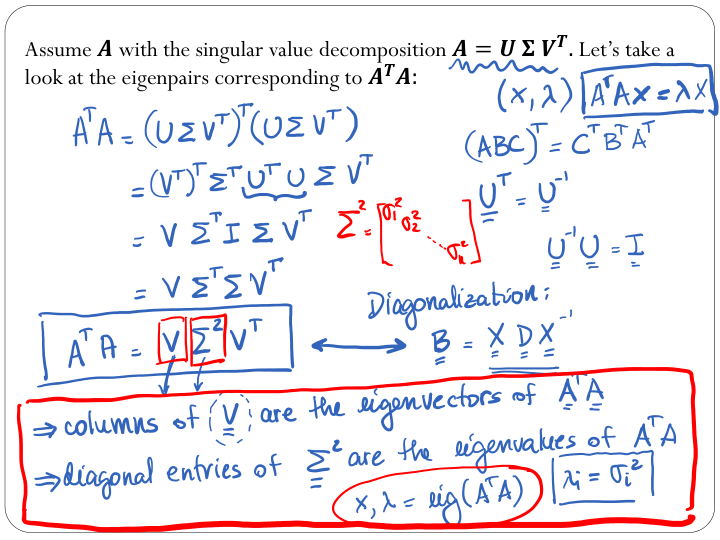

## 5. Left Singular Vectors and A A Transpose

Similarly,
$$\begin{aligned}
AA^T&=(U\Sigma V^T)(U\Sigma V^T)^T\\
&=U\Sigma V^TV\Sigma^TU^T\\
&=U(\Sigma\Sigma^T)U^T.
\end{aligned}$$
Thus the columns of $U$ form an orthonormal eigenbasis of $AA^T$:
$$AA^Tu_i=\sigma_i^2u_i\quad(1\le i\le k).$$
There are additional zero eigenvalues if $m>n$. In paired directions, $Av_i=\sigma_i u_i$ and $A^Tu_i=\sigma_i v_i$.

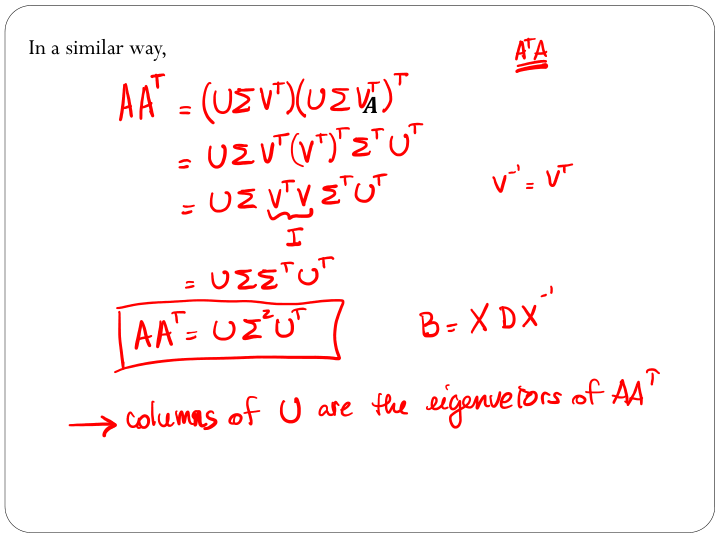

In [2]:
AtA = A.T @ A
AAt = A @ A.T
assert np.allclose(AtA @ Vt.T, Vt.T @ (Sigma.T @ Sigma))
assert np.allclose(AAt @ U, U @ (Sigma @ Sigma.T))
print('Eigenvalues of A.T @ A:', np.linalg.eigvalsh(AtA)[::-1])
print('Eigenvalues of A @ A.T:', np.linalg.eigvalsh(AAt)[::-1])
print('Squared singular values:', s**2)

Eigenvalues of A.T @ A: [30.  2. -0.]
Eigenvalues of A @ A.T: [30.  2.  0. -0.]
Squared singular values: [30.  2.  0.]


## 6. Constructing an SVD from Eigenpairs

The lecture construction is:

1. Form $B=A^TA$ and compute its eigenpairs.
2. Choose an orthonormal eigenbasis $v_i$ and sort eigenvalues in descending order. Put these vectors into $V$.
3. Set $\sigma_i=\sqrt{\lambda_i}$ and build $\Sigma$ with the required dimensions.
4. For every **positive** singular value, compute $u_i=Av_i/\sigma_i$.
5. Complete the remaining columns of $U$ with an orthonormal basis of $\ker(A^T)$.

For positive $\sigma_i,\sigma_j$,
$$u_i^Tu_j=\frac{v_i^TA^TAv_j}{\sigma_i\sigma_j}
=\frac{\sigma_j^2v_i^Tv_j}{\sigma_i\sigma_j}=\delta_{ij}.$$
This verifies that the computed left singular vectors are orthonormal. If an eigenvalue is repeated, choose an orthonormal basis within its eigenspace.

The slide formula $U=AV\Sigma^{-1}$ assumes a square invertible $\Sigma$. In a full column rank tall problem it gives $U_R=AV\Sigma_R^{-1}$, not the full $U$. Never divide by a zero singular value.

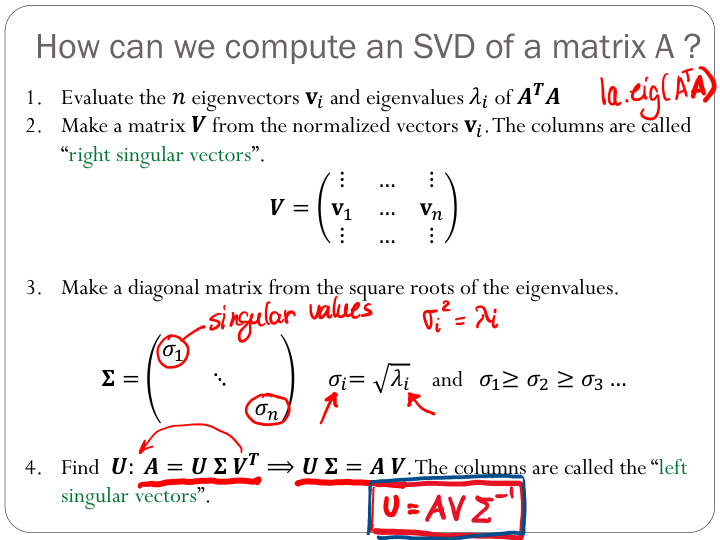

<details>
<summary>Example: Construct an SVD by hand</summary>

Let
$$A=\begin{bmatrix}3&0\\0&0\\0&2\end{bmatrix}.$$
Construct a full SVD.

<details>
<summary>Solution</summary>

We have $A^TA=\operatorname{diag}(9,4)$, so $V=I_2$ and $\sigma_1=3,\sigma_2=2$.
$$u_1=\begin{bmatrix}1\\0\\0\end{bmatrix},\quad u_2=\begin{bmatrix}0\\0\\1\end{bmatrix}.$$
Complete the basis with $u_3=(0,1,0)^T$. Then
$$U=\begin{bmatrix}1&0&0\\0&0&1\\0&1&0\end{bmatrix},\quad
\Sigma=\begin{bmatrix}3&0\\0&2\\0&0\end{bmatrix},\quad V^T=I_2.$$
Multiplying recovers $A$. The reduced form drops $u_3$ and the last zero row of $\Sigma$.

</details>
</details>

In [3]:
B = np.array([[3., 0.], [0., 0.], [0., 2.]])
lam, W = np.linalg.eigh(B.T @ B)
order = np.argsort(lam)[::-1]
lam_sorted = lam[order]
V_example = W[:, order]
s_example = np.sqrt(lam_sorted)
U_example = (B @ V_example) / s_example
assert np.allclose(U_example.T @ U_example, np.eye(2))
assert np.allclose((U_example * s_example) @ V_example.T, B)
print('Singular values:', s_example)
print('Reduced U:', U_example, sep='\n')

Singular values: [3. 2.]
Reduced U:
[[1. 0.]
 [0. 0.]
 [0. 1.]]


### Numerical implementation and nonuniqueness

The eigenpair construction explains the mathematics, but explicitly forming $A^TA$ can lose information about small singular values. For full column rank matrices,
$$\kappa_2(A^TA)=\kappa_2(A)^2.$$
Production SVD algorithms normally avoid this construction. Use `np.linalg.svd(A)` directly. Use `np.linalg.eigh` for a real symmetric matrix when illustrating the eigenpair derivation.

Singular vectors are not unique. Simultaneously replacing $u_i,v_i$ by $-u_i,-v_i$ preserves $\sigma_i u_iv_i^T$. Repeated singular values permit a shared orthogonal change of basis within the corresponding subspaces. Compare reconstructions, singular values, and subspaces rather than requiring identical vectors from different implementations.

## 7. Why Singular Values Are Nonnegative

A real symmetric matrix $B$ is **positive definite** if $x^TBx>0$ for every $x\ne0$, and **positive semidefinite** if $x^TBx\ge0$ for every $x\ne0$.

For every $x\in\mathbb R^n$,
$$x^TA^TAx=(Ax)^T(Ax)=\|Ax\|_2^2\ge0.$$
Thus $A^TA$ is symmetric positive semidefinite. If $A^TAx=\lambda x$ and $x\ne0$, then
$$\lambda=\frac{x^TA^TAx}{x^Tx}=\frac{\|Ax\|_2^2}{\|x\|_2^2}\ge0.$$
Consequently $\sigma_i=\sqrt{\lambda_i}\ge0$. This does not mean the entries or eigenvalues of $A$ are nonnegative.

Moreover, $A^TA$ is positive definite exactly when $\ker(A)=\{0\}$, equivalently when $A$ has full column rank. A wide matrix cannot have full column rank.

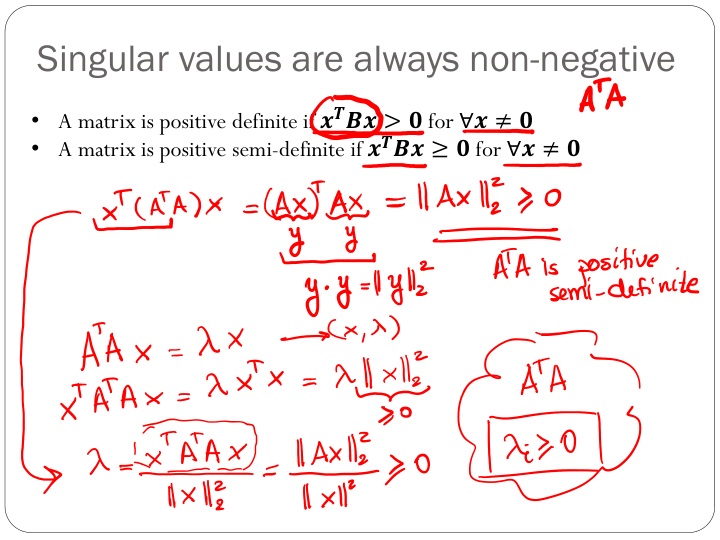

<details>
<summary>Example: Semidefinite versus definite</summary>

For $A=\begin{bmatrix}1&2\\2&4\end{bmatrix}$, determine whether $A^TA$ is positive definite.

<details>
<summary>Solution</summary>

It is positive semidefinite, but not positive definite. For nonzero $x=(-2,1)^T$, $Ax=0$, hence $x^TA^TAx=0$. Since $\det(A)=0$ and $\|A\|_F^2=25$, its singular values are $5,0$.

</details>
</details>

In [4]:
C = np.array([[1., 2.], [2., 4.]])
x_null = np.array([-2., 1.])
assert np.allclose(C @ x_null, 0)
assert np.allclose(np.linalg.svd(C, compute_uv=False), [5., 0.])
print('Quadratic form at null vector:', x_null @ C.T @ C @ x_null)
print('Eigenvalues of C.T @ C:', np.linalg.eigvalsh(C.T @ C))

Quadratic form at null vector: 0.0
Eigenvalues of C.T @ C: [ 0. 25.]


## 8. Computational Cost

The lecture gives the representative cost model
$$C_{\mathrm{SVD}}\approx\alpha(mn^2+n^3),$$
with $\alpha$ roughly $4$ to $10$ or more, depending on the algorithm and requested output. This form is intended for a tall or square matrix, $m\ge n$. For square matrices, the cost is $O(n^3)$. For a very tall matrix it is $O(mn^2)$; one cannot simplify to $O(n^3)$ while allowing $m$ to grow independently.

For a wide matrix, apply a corresponding model to $A^T$, giving $O(nm^2+m^3)$ for an economy computation. Computing an explicit full orthogonal basis can require extra work and storage.

The lecture compares square SVD with matrix multiplication at approximately $n^3$ multiply-add operations under its counting convention, LU factorization at approximately $2n^3/3$ flops, and Cholesky at approximately $n^3/3$ flops. Conventional scalar flop counting gives about $2n^3$ for dense matrix multiplication. These operations all have cubic classical scaling but different constants and purposes; SVD usually costs more.

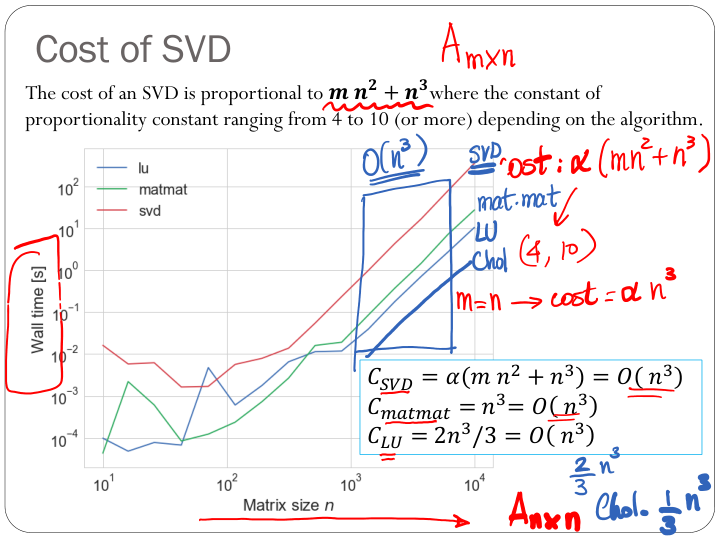

<details>
<summary>Example: Scaling the dimensions</summary>

Under $C\approx\alpha(mn^2+n^3)$, what happens when both dimensions double? What if only $m$ doubles?

<details>
<summary>Solution</summary>

Doubling both dimensions multiplies each term by $8$, so the modeled cost increases by a factor of $8$.

Doubling only $m$ gives ratio $(2mn^2+n^3)/(mn^2+n^3)=(2m+n)/(m+n)$. It approaches $2$ for $m\gg n$; it is not always exactly $2$.

</details>
</details>

## 9. Useful Consequences and Connection to Least Squares

The following consequences connect this factorization to earlier lectures:
$$A=\sum_{i=1}^{r}\sigma_i u_iv_i^T,\qquad r=\operatorname{rank}(A).$$
The column space is spanned by $u_1,\ldots,u_r$ and the row space by $v_1,\ldots,v_r$. The remaining full right singular vectors span $\ker(A)$; the remaining full left singular vectors span $\ker(A^T)$.

Orthogonal invariance yields
$$\|A\|_2=\sigma_1,\qquad\|A\|_F=\sqrt{\sum_{i=1}^{k}\sigma_i^2}.$$
For a full rank matrix, the ratio of the largest to the smallest retained singular value describes its 2-norm conditioning. For a nonzero rank deficient matrix, including a zero singular value makes this ratio infinite. For the zero matrix the direct ratio is undefined; a condition number convention is needed.

For least squares, define the pseudoinverse using only the positive singular values:
$$A^+=\sum_{i=1}^{r}\frac{1}{\sigma_i}v_iu_i^T,\qquad x_*=A^+b.$$
This is the minimum norm least squares solution. In floating point, a tolerance determines which singular values are treated as zero. These applications extend the core lecture material.

In [5]:
b = np.array([1., 2., 0., 3.])
x_star = np.linalg.pinv(A) @ b
x_lstsq = np.linalg.lstsq(A, b, rcond=None)[0]
residual = b - A @ x_star
assert np.allclose(x_star, x_lstsq)
assert np.allclose(A.T @ residual, 0)
assert np.isclose(np.linalg.norm(A, 2), s[0])
assert np.isclose(np.linalg.norm(A, 'fro'), np.linalg.norm(s))
print('Minimum norm solution:', x_star)
print('Residual norm:', np.linalg.norm(residual))

Minimum norm solution: [0.233333 0.233333 0.466667]
Residual norm: 2.0493901531919194


### Visualizing orthogonal directions and stretching

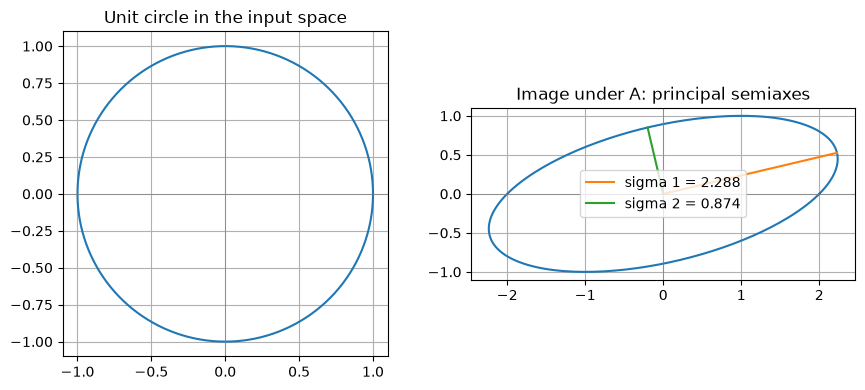

In [6]:
theta = np.linspace(0, 2*np.pi, 300)
circle = np.vstack((np.cos(theta), np.sin(theta)))
D = np.array([[2., 1.], [0., 1.]])
Ud, sd, Vtd = np.linalg.svd(D)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].plot(circle[0], circle[1])
axes[0].set_title('Unit circle in the input space')
ellipse = D @ circle
axes[1].plot(ellipse[0], ellipse[1])
for i in range(2):
    direction = sd[i] * Ud[:, i]
    axes[1].plot([0, direction[0]], [0, direction[1]], label=f'sigma {i+1} = {sd[i]:.3f}')
axes[1].set_title('Image under A: principal semiaxes')
axes[1].legend()
for ax in axes:
    ax.set_aspect('equal')
    ax.grid(True)
    ax.axhline(0, color='gray', linewidth=.5)
    ax.axvline(0, color='gray', linewidth=.5)
plt.tight_layout()
plt.show()

## 10. Review Checklist

<table>
<thead><tr><th>Concept</th><th>What to check</th></tr></thead>
<tbody>
<tr><td>Full SVD</td><td>U is m by m, Sigma is m by n, V transpose is n by n.</td></tr>
<tr><td>Reduced SVD</td><td>Use k = min(m,n), including zero singular values.</td></tr>
<tr><td>Right singular vectors</td><td>Columns of V; eigenvectors of A transpose A.</td></tr>
<tr><td>Left singular vectors</td><td>Columns of U; eigenvectors of A A transpose.</td></tr>
<tr><td>Eigenvalues</td><td>Square the singular values and include dimension-dependent extra zeros.</td></tr>
<tr><td>Recovering u</td><td>Divide A v by sigma only when sigma is positive.</td></tr>
<tr><td>Nonnegative values</td><td>Use x transpose A transpose A x = norm(A x) squared.</td></tr>
<tr><td>Cost</td><td>Cubic for square matrices; preserve both dimensions otherwise.</td></tr>
</tbody></table>

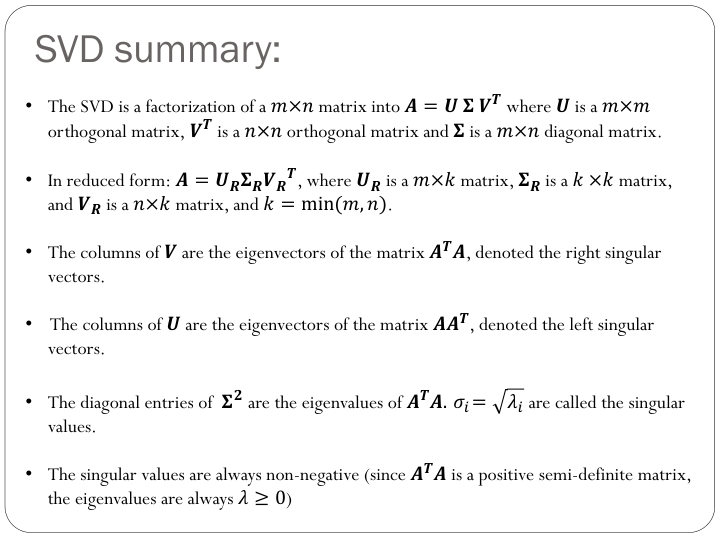

<details>
<summary>Example: Quick concept check</summary>

Decide whether each claim is true.

1. Every real rectangular matrix has an SVD.
2. All singular values are positive.
3. Reduced SVD always removes every zero singular value.
4. $A^TA$ and $AA^T$ always have the same number of zero eigenvalues.
5. $V^T$ contains right singular vectors as its rows.

<details>
<summary>Solution</summary>

1. True.
2. False. Zero singular values occur in rank deficient matrices.
3. False. The lecture's reduced SVD keeps $\min(m,n)$ entries.
4. False. Their dimensions can differ. Their nonzero eigenvalues agree with multiplicity.
5. True. The vectors themselves are columns of $V$.

</details>
</details>

## 11. Course Practice with Worked Solutions

<details>
<summary>Example: Reduced shapes for a 10 by 13 matrix</summary>

For $A\in\mathbb R^{10\times13}$, determine the shapes of $U_R$, $\Sigma_R$, and $V_R$.

<details>
<summary>Solution</summary>

$k=\min(10,13)=10$. Thus $U_R$ is $10\times10$, $\Sigma_R$ is $10\times10$, and $V_R$ is $13\times10$. The factor actually appearing on the right is $V_R^T$, of shape $10\times13$.

</details>
</details>

<details>
<summary>Example: Eigenvalues from a rank one rectangular matrix</summary>

For $A=\begin{bmatrix}2&1\\0&0\\0&0\end{bmatrix}$, find the eigenvalues of $A^TA$ in descending order.

<details>
<summary>Solution</summary>

$A^TA=\begin{bmatrix}4&2\\2&1\end{bmatrix}$. Its characteristic polynomial is $(4-\lambda)(1-\lambda)-4=\lambda(\lambda-5)$. Therefore $\lambda_1=5$ and $\lambda_2=0$, and the singular values are $\sqrt5,0$.

</details>
</details>

<details>
<summary>Example: Which factorization reveals eigenvalues?</summary>

Choose the factorization whose diagonal entries directly give the eigenvalues of $A$:

1. $A=LU$, with triangular factors.
2. $A=U\Sigma V^T$, with two orthogonal factors.
3. $A=QDQ^T$, with $Q$ orthogonal and $D$ diagonal.
4. $A=QR$, with $R$ upper triangular.

<details>
<summary>Solution</summary>

Choice 3: $Aq_i=d_iq_i$, since $Q^TQ=I$. Such a real orthogonal diagonalization exists for real symmetric matrices. In the SVD, the two orthogonal bases can differ, so its singular values generally are not eigenvalues of $A$. Neither the LU nor QR factorization is generally a similarity transformation.

</details>
</details>

<details>
<summary>Example: Predicting SVD runtime in both directions</summary>

A $3000\times4000$ SVD takes 6 seconds. Estimate the time for $15000\times20000$. Separately, a square $4000\times4000$ SVD takes 6 seconds; what size takes 384 seconds under cubic scaling?

<details>
<summary>Solution</summary>

In the first case both dimensions increase by $5$, so the cost increases by $5^3=125$. The estimate is $6\cdot125=750$ seconds.

In the second case the time ratio is $384/6=64$, so the dimension ratio is $\sqrt[3]{64}=4$. The new matrix is $16000\times16000$. These estimates assume comparable algorithms and hardware.

</details>
</details>

<details>
<summary>Example: Sorting eigenvalues and singular values</summary>

The diagonal scaling entries in a supplied factorization are $7,8,5$. Find the eigenvalues of $A^TA$ in descending order. In another problem, $A^TA$ has eigenvalues $3,12,7,14$; find the largest singular value.

<details>
<summary>Solution</summary>

Square and then sort: the eigenvalues are $64,49,25$. The supplied factorization need not display its scaling entries in descending order even though the canonical ordered SVD does.

In the second case $\sigma_1=\sqrt{\max(3,12,7,14)}=\sqrt{14}\approx3.74166$. Taking the first diagonal entry without sorting would be wrong.

</details>
</details>

<details>
<summary>Example: Recover U from A V</summary>

You are given
$$AV=\begin{bmatrix}-3.173538&-0.627280&-1.527554\\-2.853700&-2.127708&1.199336\\-2.492956&3.324020&0.508392\end{bmatrix}$$
and ordered eigenvalues of $A^TA$ equal to $25,16,4$. Find $U$.

<details>
<summary>Solution</summary>

The singular values are $5,4,2$. Divide column $j$ of $AV$ by $\sigma_j$:
$$U\approx\begin{bmatrix}-0.634708&-0.156820&-0.763777\\-0.570740&-0.531927&0.599668\\-0.498591&0.831005&0.254196\end{bmatrix}.$$
In NumPy this is `U = AV / np.array([5., 4., 2.])`. A one-dimensional divisor broadcasts over columns. Rounded course data can make orthogonality approximate.

</details>
</details>

<details>
<summary>Example: Compute SVD factors from supplied eigenpairs</summary>

A square nonsingular matrix $A$ and eigenpair arrays `X`, `s` satisfy $A^TA=X\operatorname{diag}(s)X^{-1}$. Columns of `X` are an orthogonal eigenbasis, possibly requiring normalization. Construct `U`, a one-dimensional `Sigma`, and `Vtransp` without an SVD routine.

<details>
<summary>Solution</summary>

Sort the eigenpairs together, normalize the columns, and use $u_i=Av_i/\sqrt{s_i}$.

```python
order = np.argsort(s)[::-1]
Sigma = np.sqrt(s[order])
V = X[:, order] / np.linalg.norm(X[:, order], axis=0)
Vtransp = V.T
U = (A @ V) / Sigma
```

Nonsingularity ensures positive denominators. If repeated eigenvalues come with a nonorthogonal basis, orthonormalize within each repeated eigenspace first.

</details>
</details>

<details>
<summary>Example: Solve with an SVD through two multiplication functions</summary>

Let $A$ be square and nonsingular with $A=U\Sigma V^T$. You are given the one-dimensional arrays `b` and `sigma`, plus functions `right_multiply_with_U(y)` returning `y @ U` and `left_multiply_with_V(y)` returning `V @ y`. Find $x$ satisfying $Ax=b$ in $O(n^2)$ time.

<details>
<summary>Solution</summary>

The formula is $x=V\Sigma^{-1}U^Tb$. For a real one-dimensional NumPy vector, the entries of `b @ U` are the entries of $U^Tb$, because $(b^TU)^T=U^Tb$. Thus:

```python
y = right_multiply_with_U(b)
x = left_multiply_with_V(y / sigma)
```

There are two dense matrix-vector products, each $O(n^2)$, and one $O(n)$ elementwise division. No matrix inverse or reconstructed $A$ is needed. The identity uses real vectors; complex data requires conjugation.

</details>
</details>

In [7]:
# Verify both course coding patterns on an independent nonsingular example.
A_check = np.array([[3., 1.], [0., 2.]])
eigvals, eigvecs = np.linalg.eigh(A_check.T @ A_check)
order = np.argsort(eigvals)[::-1]
Sigma_check = np.sqrt(eigvals[order])
V_check = eigvecs[:, order]
U_check = (A_check @ V_check) / Sigma_check
assert np.allclose(U_check.T @ U_check, np.eye(2))
assert np.allclose((U_check * Sigma_check) @ V_check.T, A_check)
b_check = np.array([2., -1.])
def right_multiply_with_U(y):
    return y @ U_check
def left_multiply_with_V(y):
    return V_check @ y
x_check = left_multiply_with_V(right_multiply_with_U(b_check) / Sigma_check)
assert np.allclose(A_check @ x_check, b_check)
print('Reconstruction and linear solve checks passed.')

Reconstruction and linear solve checks passed.
